# 01 – Khám phá dữ liệu (EDA): Adult Census Income
Notebook gọi `src/eda.py`; mọi số liệu và biểu đồ được tính trực tiếp từ `data/raw/adult.csv`.
EDA mang tính **mô tả**, chạy trên toàn bộ dữ liệu; không tham số tiền xử lý/mô hình nào được học ở đây.

In [1]:
import sys, warnings; sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import pandas as pd; from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
import eda
r = eda.run()
FIG = '../results/figures/eda/'

## 1–4. Kích thước, kiểu dữ liệu, giá trị thiếu, trùng lặp

In [2]:
print('Kích thước:', r['shape'], '| Dòng trùng hoàn toàn:', r['dups'],
      "| Dòng có workclass='?' và occupation='?' cùng lúc:", r['wc_and_occ_missing'])
r['info']

Kích thước: (32561, 15) | Dòng trùng hoàn toàn: 24 | Dòng có workclass='?' và occupation='?' cùng lúc: 1836


,dtype,n_unique,n_question_mark,n_nan,pct_question_mark
age,int64,73,0,0,0.00
workclass,str,9,1836,0,5.64
fnlwgt,int64,21648,0,0,0.00
education,str,16,0,0,0.00
education.num,int64,16,0,0,0.00
marital.status,str,7,0,0,0.00
occupation,str,15,1843,0,5.66
relationship,str,6,0,0,0.00
race,str,5,0,0,0.00
sex,str,2,0,0,0.00


In [3]:
r['miss']  # tỷ lệ >50K của các dòng có/không có '?'

,n_rows,rate_gt50K
có '?',2399,0.1388
không có '?',30162,0.2489


In [4]:
raw = pd.read_csv('../data/raw/adult.csv')
raw.loc[raw.occupation == '?', 'workclass'].value_counts()

workclass
?               1836
Never-worked       7
Name: count, dtype: int64

**Nhận xét.**
- 32.561 dòng × 15 cột (6 số nguyên, 8 phân loại, 1 nhãn). Không có NaN; giá trị thiếu được mã hóa bằng `'?'` ở `workclass` (5,64%), `occupation` (5,66%), `native.country` (1,79%).
- 1.836 dòng thiếu **đồng thời** `workclass` và `occupation` → thiếu có cấu trúc, không ngẫu nhiên. 7 dòng `occupation='?'` còn lại đều có `workclass='Never-worked'` (chưa từng đi làm nên không có nghề).
- Dòng có `'?'` có tỷ lệ >50K **13,9%** so với **24,9%** ở dòng đầy đủ → việc thiếu mang thông tin. Đây là căn cứ giữ `'?'` thành hạng mục `"Unknown"` thay vì xóa dòng hay điền mode.
- 24 dòng trùng hoàn toàn (0,07%) được giữ lại (có thể là các cá nhân khác nhau cùng hồ sơ).

## 5. Phân phối nhãn thu nhập

,count,pct
income,,
<=50K,24720,75.92
>50K,7841,24.08


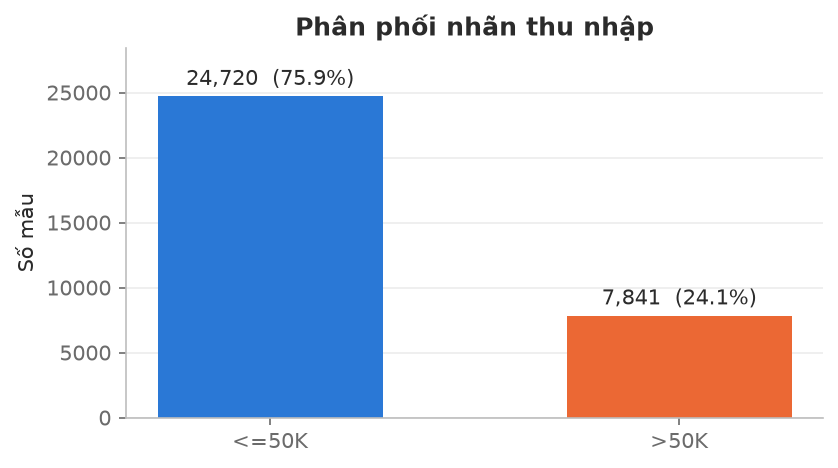

In [5]:
display(r['label']); display(Image(FIG + '01_income_distribution.png'))

**Nhận xét.** Mất cân bằng lớp: `<=50K` 75,92% – `>50K` 24,08% (≈ 3,15 : 1).
Bộ phân lớp "luôn đoán <=50K" đạt Accuracy 75,92% nhưng Recall lớp >50K = 0. Vì vậy thực nghiệm dùng **F1 của lớp >50K** làm tiêu chí chọn siêu tham số và báo cáo thêm Precision, Recall, ROC-AUC, PR-AUC (PR-AUC của bộ đoán ngẫu nhiên ≈ 0,24).

## 6. Thuộc tính số

In [6]:
display(r['num_desc'].round(2)); display(r['by_class'].round(2))

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero
age,32561.0,38.58,13.64,17.0,28.0,37.0,48.0,90.0,0.56,0.00
fnlwgt,32561.0,189778.37,105549.98,12285.0,117827.0,178356.0,237051.0,1484705.0,1.45,0.00
education.num,32561.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0,-0.31,0.00
capital.gain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,99999.0,11.95,91.67
capital.loss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,4356.0,4.59,95.33
hours.per.week,32561.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0,0.23,0.00


<=50K       >50K
age            mean        36.78      44.25
               median      34.00      44.00
fnlwgt         mean    190340.87  188005.00
               median  179465.00  176101.00
education.num  mean         9.60      11.61
               median       9.00      12.00
capital.gain   mean       148.75    4006.14
               median       0.00       0.00
capital.loss   mean        53.14     195.00
               median       0.00       0.00
hours.per.week mean        38.84      45.47
               median      40.00      40.00

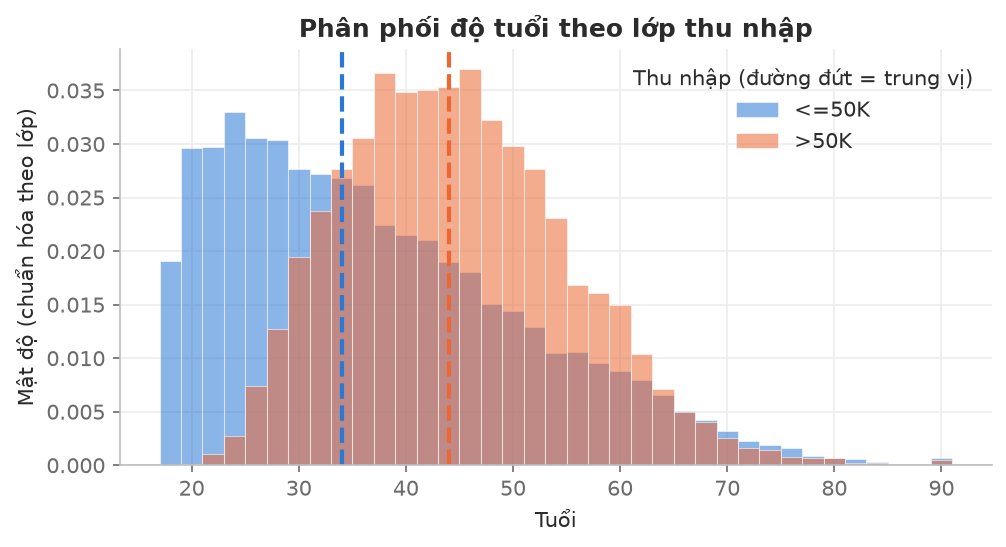

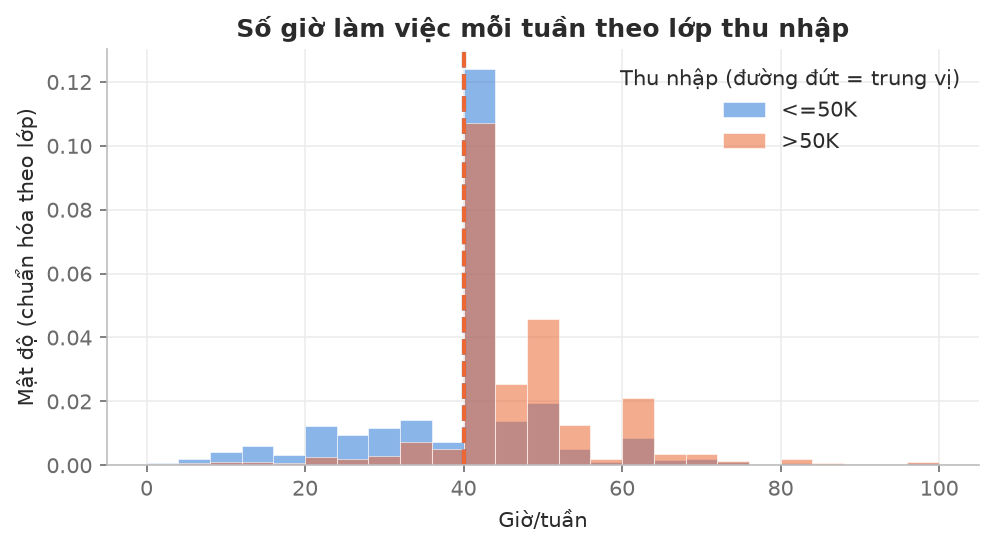

In [7]:
display(Image(FIG + '02_age.png')); display(Image(FIG + '03_hours_per_week.png'))

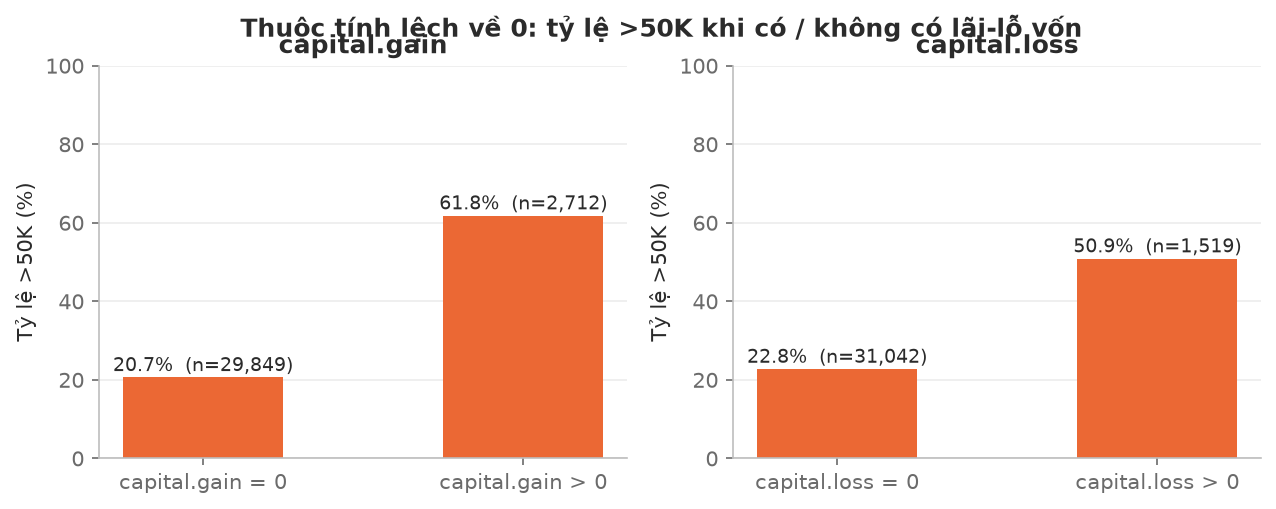

In [8]:
display(Image(FIG + '07_capital_zero_vs_nonzero.png'))

In [9]:
print('Số dòng hours.per.week = 99:', (raw['hours.per.week'] == 99).sum())
print('Số dòng capital.gain = 99999:', (raw['capital.gain'] == 99999).sum(),
      raw.loc[raw['capital.gain'] == 99999, 'income'].value_counts().to_dict())

Số dòng hours.per.week = 99: 85
Số dòng capital.gain = 99999: 159 {'>50K': 159}


**Nhận xét.**
- **age**: trung vị 34 (<=50K) so với 44 (>50K); lớp >50K hầu như không có người dưới 25 tuổi.
- **hours.per.week**: trung vị cả hai lớp đều 40, nhưng trung bình 38,8 so với 45,5 → lớp >50K tập trung nhiều hơn ở mức >40 giờ.
- **capital.gain / capital.loss**: lệch rất mạnh (skew 11,95 và 4,59), lần lượt **91,67% và 95,33% bằng 0**. Giá trị 99.999 xuất hiện ở 159 dòng, **tất cả** đều >50K → dấu hiệu giá trị bị chặn trên (top-coding) của nguồn điều tra. Đây là lý do CategoricalNB dùng bộ rời rạc hóa riêng "0 / phần dương".
- **fnlwgt** (trọng số mẫu của điều tra) gần như không khác giữa hai lớp (trung vị 179.465 vs 176.101; Pearson với nhãn −0,009).
- **education.num** chênh rõ: trung vị 9 vs 12.

## 7. Thuộc tính phân loại

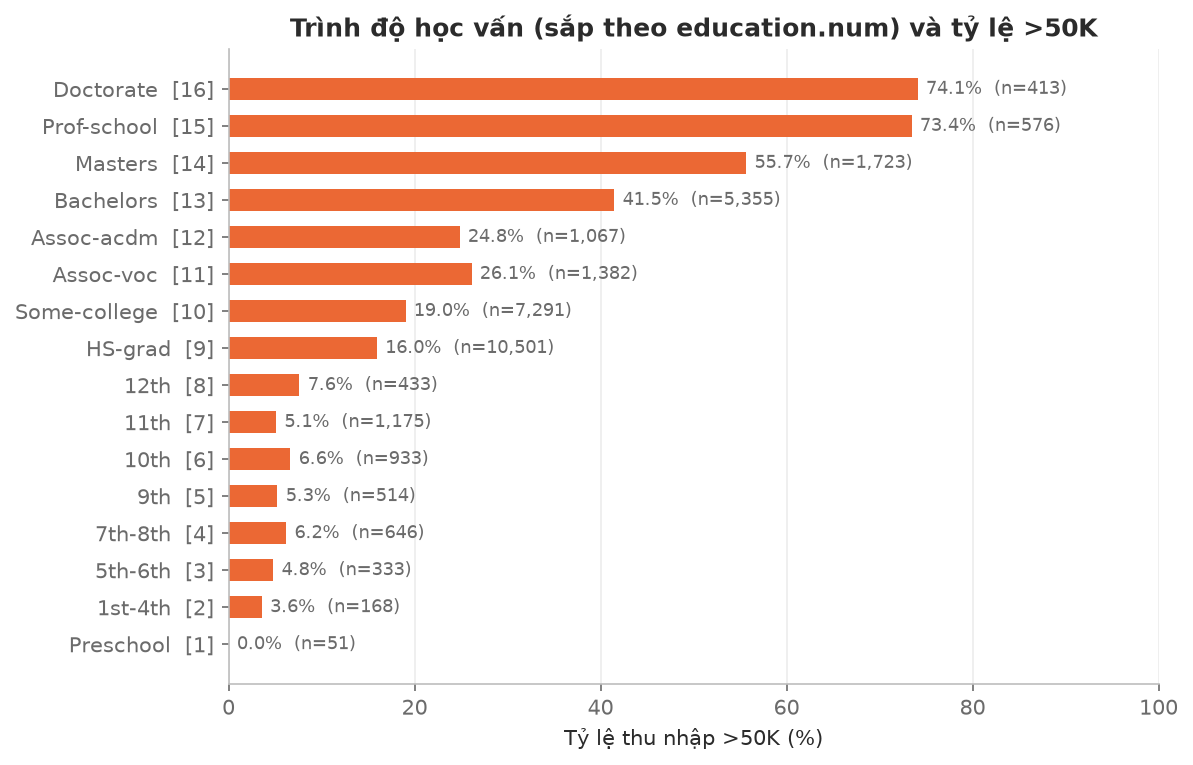

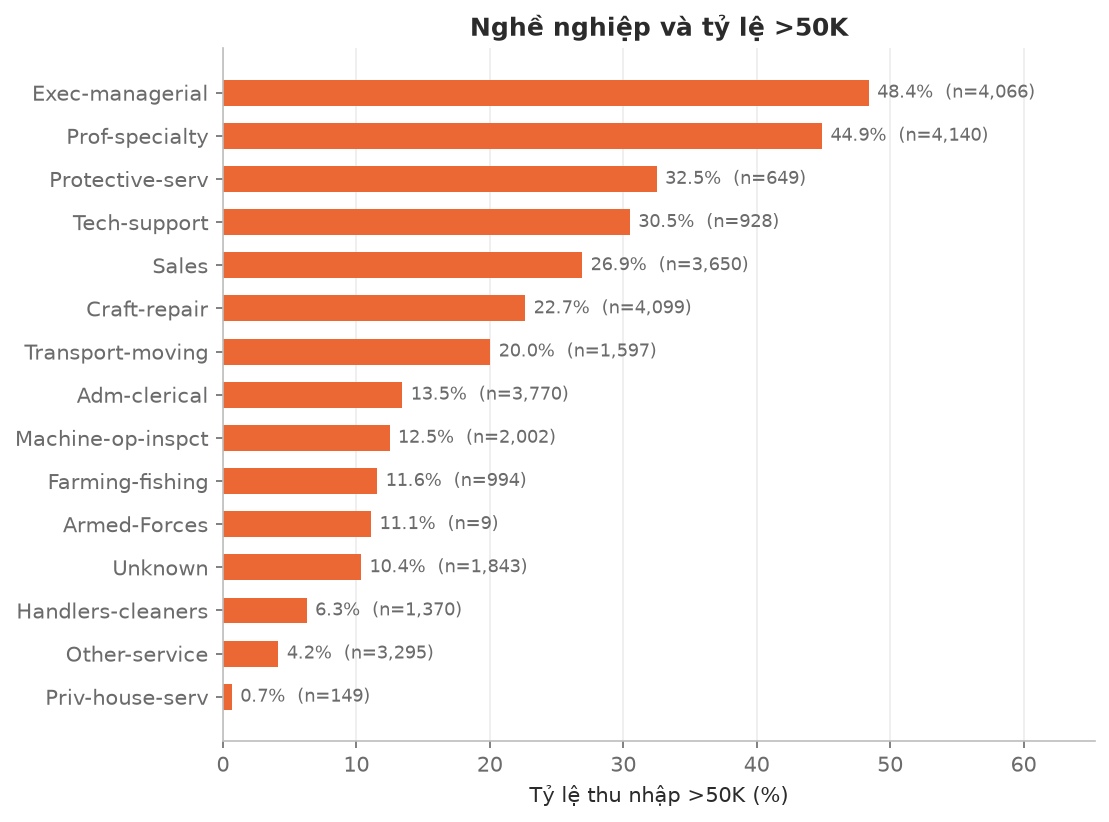

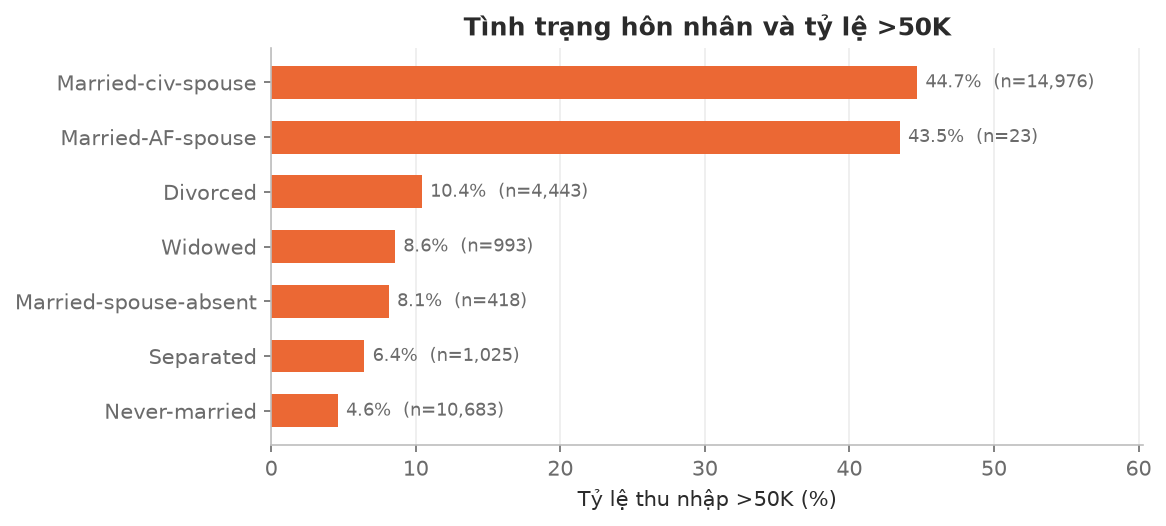

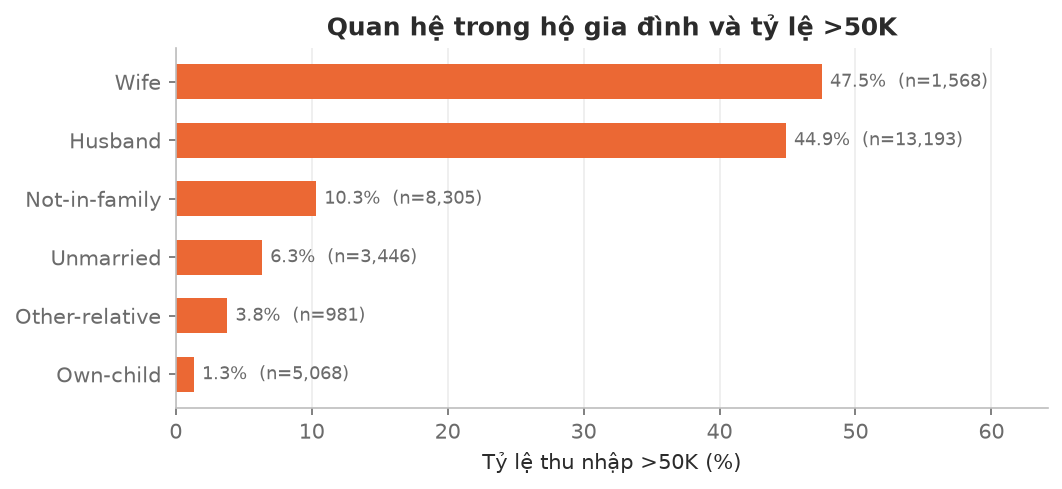

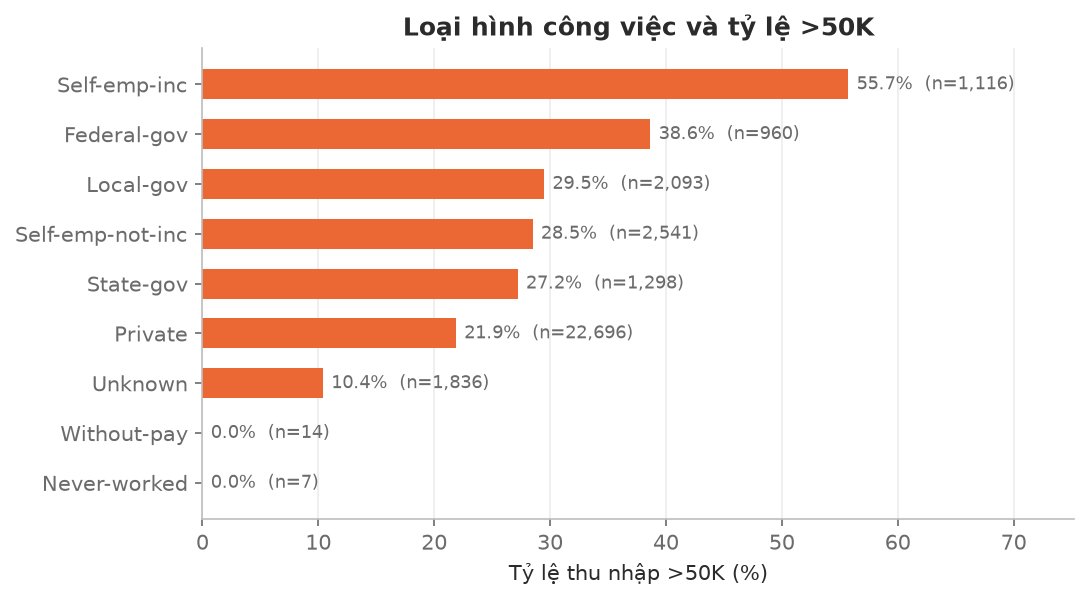

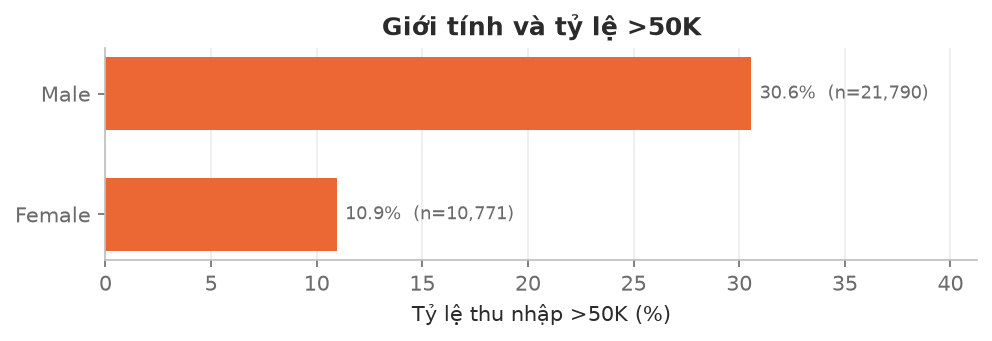

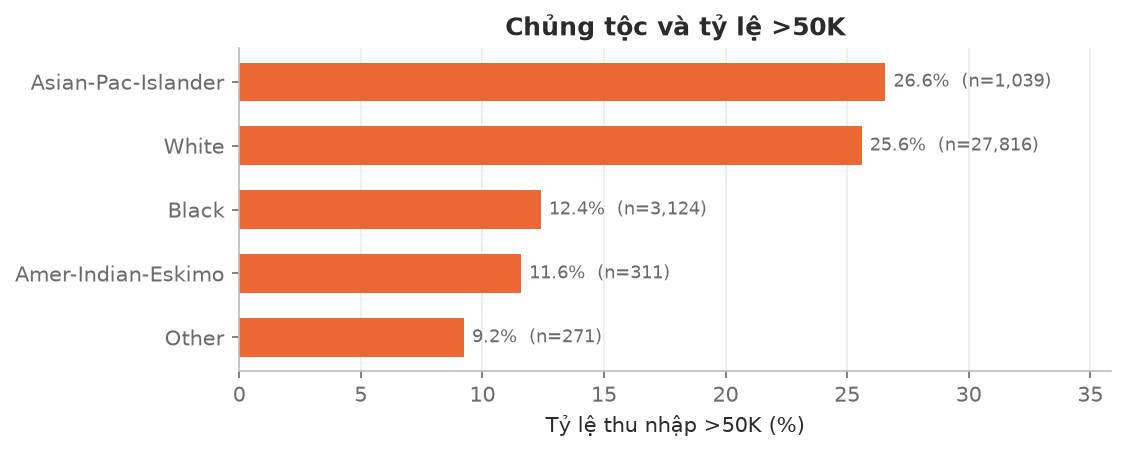

In [10]:
for f in ['04_education.png', '05_occupation.png', '06a_marital_status.png', '06b_relationship.png',
          '06c_workclass.png', '06d_sex.png', '06e_race.png']:
    display(Image(FIG + f))

In [11]:
nc = r['rates'][r['rates'].feature == 'native.country'].sort_values('count', ascending=False)
print('Số quốc gia (kể cả Unknown):', len(nc), '| Tỷ lệ United-States:', round(nc['count'].iloc[0] / nc['count'].sum(), 4))
nc.head(8)

Số quốc gia (kể cả Unknown): 42 | Tỷ lệ United-States: 0.8959


,feature,category,count,rate_gt50K
82,native.country,United-States,29170,0.2458
69,native.country,Mexico,643,0.0513
83,native.country,Unknown,583,0.2504
73,native.country,Philippines,198,0.3081
54,native.country,Germany,137,0.3212
45,native.country,Canada,121,0.3223
76,native.country,Puerto-Rico,114,0.1053
51,native.country,El-Salvador,106,0.0849


**Nhận xét.**
- **education**: tỷ lệ >50K tăng gần đơn điệu theo `education.num`. `education` và `education.num` ánh xạ 1–1 (kiểm tra trong `check_design.py`) → bỏ `education`, giữ `education.num` (giữ được thứ tự).
- **occupation**: Exec-managerial (48,4%) và Prof-specialty (44,9%) cao nhất; Priv-house-serv (0,7%) và Other-service (4,2%) thấp nhất.
- **marital.status / relationship**: Married-civ-spouse 44,7%; Husband 44,9%, Wife 47,5%; Own-child chỉ 1,3%; Never-married 4,6%.
- **sex**: Male 30,6% so với Female 10,9%. **race**: White 25,6%, Asian-Pac-Islander 26,6%, Black 12,4%. Các chênh lệch này phản ánh dữ liệu lịch sử (điều tra dân số Mỹ 1994), **không** phải quan hệ nhân quả và không được dùng mô hình để ra quyết định về cá nhân.
- **native.country**: 42 giá trị, United-States chiếm 89,6% → nhiều hạng mục hiếm (Holand-Netherlands chỉ 1 dòng), cần cơ chế xử lý hạng mục chưa thấy.
- Một số hạng mục rất nhỏ (Armed-Forces n=9, Never-worked n=7, Without-pay n=14): tỷ lệ không đáng tin cậy thống kê; với CategoricalNB, smoothing `alpha` có vai trò quan trọng.

## 8–9. Mối liên hệ và thuộc tính dư thừa

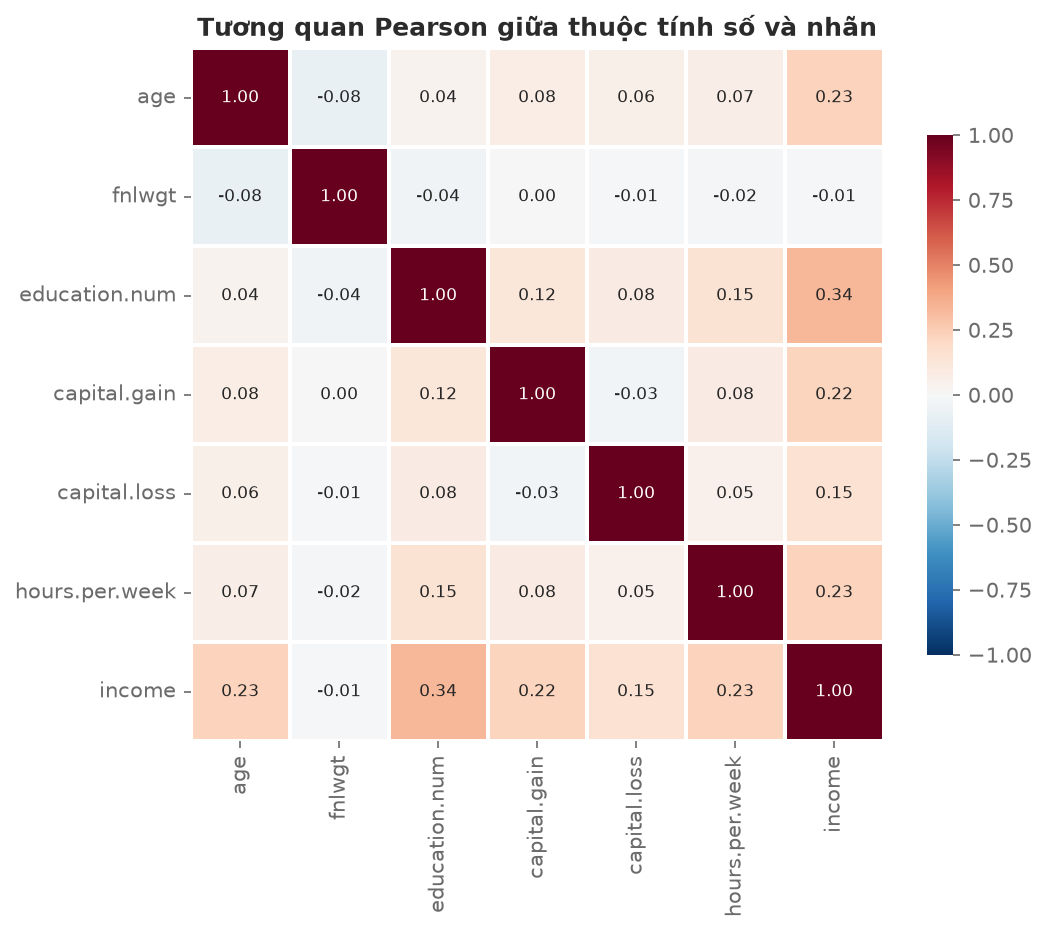

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,income
age,1.000,-0.078,0.066,0.125,0.058,0.143,0.273
fnlwgt,-0.078,1.000,-0.036,-0.006,-0.007,-0.022,-0.011
education.num,0.066,-0.036,1.000,0.119,0.075,0.167,0.330
capital.gain,0.125,-0.006,0.119,1.000,-0.067,0.093,0.278
capital.loss,0.058,-0.007,0.075,-0.067,1.000,0.060,0.141
hours.per.week,0.143,-0.022,0.167,0.093,0.060,1.000,0.269
income,0.273,-0.011,0.330,0.278,0.141,0.269,1.000


In [12]:
display(Image(FIG + '08_corr_numeric_pearson.png')); display(r['spearman'].round(3))

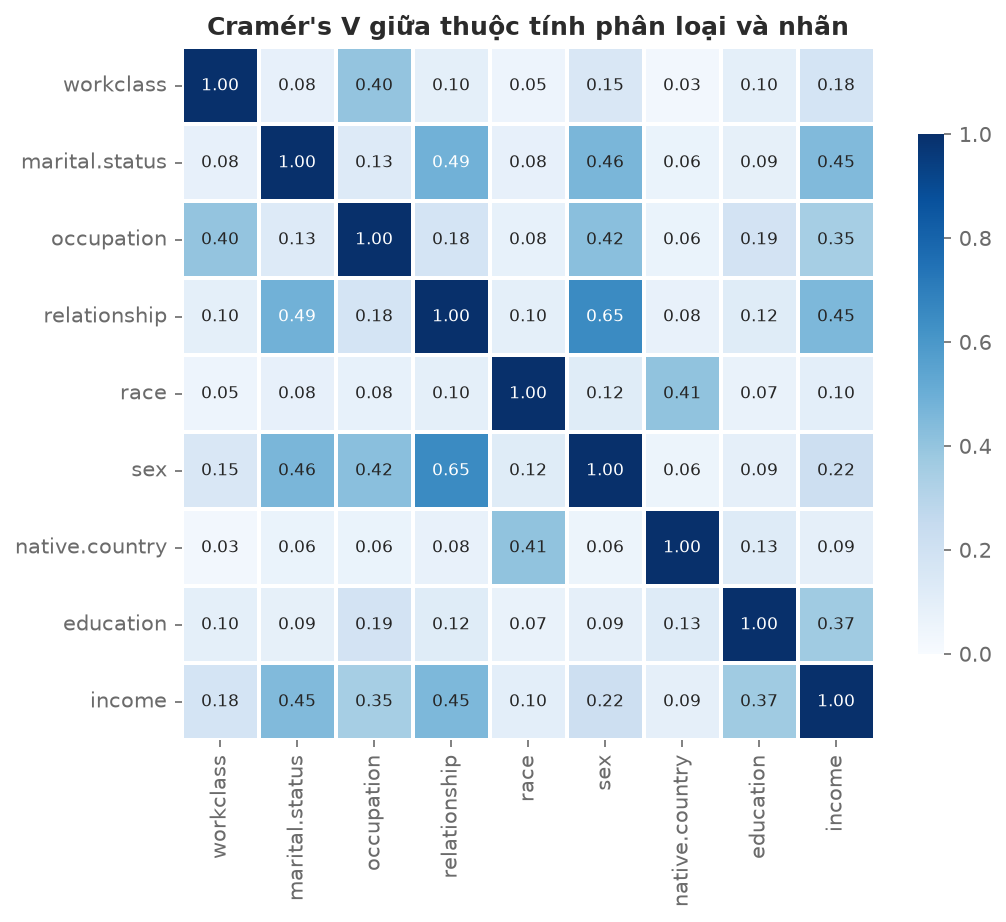

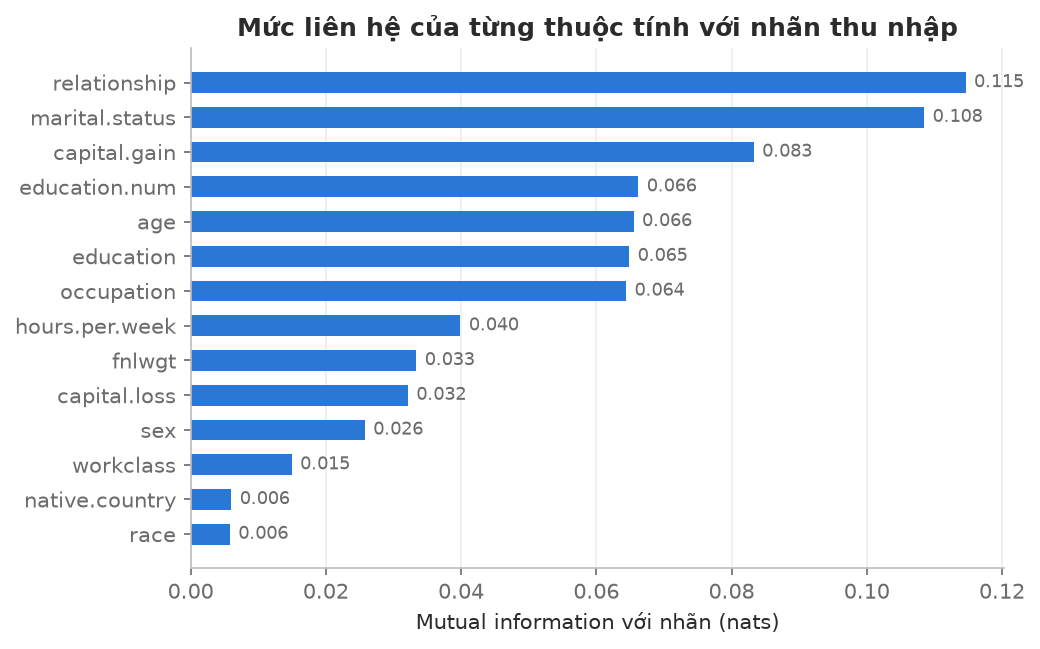

In [13]:
display(Image(FIG + '09_cramers_v_categorical.png')); display(Image(FIG + '10_mutual_information.png'))

**Nhận xét.**
- Giữa các thuộc tính số, tương quan rất yếu (|Pearson| lớn nhất ≈ 0,15: education.num – hours.per.week) → không có dư thừa tuyến tính đáng kể.
- Với nhãn: education.num (Pearson 0,335), age (0,234), hours.per.week (0,230), capital.gain (0,223).
- Giữa các thuộc tính phân loại (Cramér's V): **relationship–sex 0,65**, marital.status–relationship 0,49, marital.status–sex 0,46, occupation–sex 0,42, race–native.country 0,41, workclass–occupation 0,40.
- **Hệ quả cho Naive Bayes:** giả định độc lập có điều kiện bị vi phạm rõ (relationship "Husband/Wife" gần như xác định sex và marital.status). NB "đếm trùng" bằng chứng → xác suất dự đoán có xu hướng bị đẩy về 0/1, dù thứ hạng (ROC-AUC) vẫn có thể tốt. Decision Tree không chịu giả định này.
- Mutual information với nhãn: relationship (0,115) > marital.status (0,109) > capital.gain (0,083) > education.num (0,066) ≈ age (0,066) ≈ occupation (0,064); thấp nhất: race và native.country (0,006).
- **Quyết định:** giữ các thuộc tính tương quan để hai thuật toán được so sánh trên **cùng tập đặc trưng**; chỉ loại `education` vì trùng lặp hoàn toàn.

## 10. Tổng kết EDA → ảnh hưởng tới thiết kế
| Phát hiện | Quyết định |
|---|---|
| `'?'` ở 3 cột, thiếu có cấu trúc, liên quan tới nhãn | Hạng mục `"Unknown"` (SimpleImputer constant, trong Pipeline) |
| Mất cân bằng 76/24 | Chia phân tầng; tiêu chí chọn mô hình = F1 lớp >50K; báo cáo PR-AUC |
| capital.gain/loss >90% bằng 0 | CategoricalNB: rời rạc hóa "0 / phần dương"; GaussianNB (phụ) vi phạm giả định Gaussian nặng |
| `education` ≡ `education.num` | Bỏ `education` |
| Phụ thuộc mạnh relationship / marital.status / sex | Giữ nguyên; thảo luận như hạn chế của giả định NB |
| native.country có hạng mục hiếm/chưa thấy | Mã dành riêng cho hạng mục chưa thấy trong Train; smoothing alpha |